# Module 3 Basics: Phoenix Crime Data

**Course:** SDS 510 Data Wrangling, Module 3 (Python Data Transformation Basics badge)

**Data:** Phoenix crime stats, `crimestat.csv` (renamed from `crime-data_crime-data_crimestat.csv`), from Phoenix Open Data:
https://www.phoenixopendata.com/dataset/crime-data
* 624,147 rows, 8 columns.
* Columns: INC NUMBER, OCCURRED ON, OCCURRED TO, UCR CRIME CATEGORY, 100 BLOCK ADDR, ZIP, PREMISE TYPE, GRID.
* Records run from November 1, 2015 to December 31, 2025.

**Record format change in September 2025**

* Records through September 2, 2025 use dates like `11/01/2015  00:00`.
* Records from September 9, 2025 on use dates like `9/9/2025  10:45:00AM` (18,872 rows).
* No records fall between September 3 and September 8, 2025.
* Two new categories start with the new format: `SIMPLE ASSAULT` and `DRUG OFFENSES`. Older records spell it `DRUG OFFENSE`, without the S.
* The trends in section 5 use 2016 to 2024, so the change doesn't affect them.

**CSV used here (Google Drive):** https://drive.google.com/file/d/1sYJDsWaWNumuSCpYrvxBBOFG6yYKLIlL/view?usp=sharing

## Questions

1. How much of Phoenix crime is violent, and how much is non-violent?
2. Which zip codes have the fastest growing and shrinking violent and non-violent crime?

## Audience

The Pre-Crime Unit in the Valley. Police departments, nonprofits working on crime, and community early intervention programs can use the same results.

## 1. Setup

In our setup section, we are importing the Python packages that we're going to need for this analysis. We're importing NumPy to use its math functions, Pandas for working with the data frames, and Matplotlib for making the bar and line charts.

In [142]:
# 1.1 imports: numpy, pandas, matplotlib.pyplot

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load and inspect

Next, we're gonna load in our CSV. This is pointing to a Google Drive URL, given that the file size is too big to have in GitHub. This is setting the URL that will be used for crime stats that can be read in.

In [143]:
# 1.4 + 2.1 store the Drive URL, read the CSV into a dataframe

stats_url = 'https://drive.google.com/uc?export=download&id=1sYJDsWaWNumuSCpYrvxBBOFG6yYKLIlL'
crime_stats = pd.read_csv(stats_url)

C:\Users\sthre\AppData\Local\Temp\ipykernel_33660\1414481020.py:4: DtypeWarning: Columns (0: INC NUMBER) have mixed types. Specify dtype option on import or set low_memory=False.
  crime_stats = pd.read_csv(stats_url)


Next, we are just taking a look at the data that we've imported. Head will give us an overview of the different columns and the type of data in them.

In [ ]:
# 2.2 first 20 rows
crime_stats.head(20)

Shape tells us how many rows there are, which initially would be 624,147 with 8 columns.

In [ ]:
# 2.2 rows and columns
crime_stats.shape

Info is a breakdown of the different columns, how many non-null rows they have, and the data type.

In [ ]:
# 2.2 column types and non-null counts
crime_stats.info()

Nunique gives us the number of unique values per column, which is helpful for us to see things like there's 11 crime categories and 119 zip codes.

In [ ]:
# 2.2 unique values per column
crime_stats.nunique()

crime_stats.columns gives us the column names, which we're going to be utilizing later.

In [ ]:
# 2.3 column names
crime_stats.columns

And then we're just counting how many crimes fall under each bucket. This tells us that larceny theft is the most occurring crime across this data period, with drug offenses being at the bottom, somehow less than murder and non-negligent manslaughter.

In [145]:
# 2.4 count each crime category

crime_stats['UCR CRIME CATEGORY'].value_counts()

UCR CRIME CATEGORY
LARCENY-THEFT                            314486
BURGLARY                                  75789
MOTOR VEHICLE THEFT                       71292
AGGRAVATED ASSAULT                        59976
DRUG OFFENSE                              54972
ROBBERY                                   24181
RAPE                                       9867
ARSON                                      5961
SIMPLE ASSAULT                             4991
MURDER AND NON-NEGLIGENT MANSLAUGHTER      1604
DRUG OFFENSES                              1028
Name: count, dtype: int64

## 3. Clean

In part 3, we're going to clean the data to get it ready to display and manipulate.

First we're going to check if any of our columns have missing values.

In [146]:
# 3.1 count missing values per column
crime_stats.isna().sum()

INC NUMBER                 0
OCCURRED ON              419
OCCURRED TO           231295
UCR CRIME CATEGORY         0
100 BLOCK ADDR             0
ZIP                     6592
PREMISE TYPE            4187
GRID                    1833
dtype: int64

We are going to drop rows that have no zip, since we're going to be looking at crime statistics by zip code. If it doesn't have a zip, then I don't want to incorporate it into my final dataset. So we're going to look at anything where zip is greater than 0, and then we're gonna go ahead and apply that.

In [147]:
# 3.2 drop rows with no ZIP: keep ZIP > 0 (record shape before and after)


crime_stats = crime_stats[crime_stats['ZIP'] > 0]
crime_stats['ZIP'] = crime_stats['ZIP'].apply(int)
print(crime_stats.shape)


(617555, 8)


Then we're going to drop rows with no dates. We're doing this by running a string contains on OCCURRED ON to look for the forward slash, and finding those rows that contain that. We're using that character because that's what the date formats always have.

In [148]:
# 3.3 drop rows with no date: keep OCCURRED ON that contains '/'


crime_stats = crime_stats[crime_stats['OCCURRED ON'].str.contains('/')]
print(crime_stats.shape)

(617136, 8)


And then we're writing a function to get the year, where it's going to return a value split by looking at that forward slash and grabbing the values for the year.

In [149]:
# 3.4 write get_year, apply it to OCCURRED ON, store as year
def get_year(x):
    return int(x.split('/')[2][:4])

crime_stats['year'] = crime_stats['OCCURRED ON'].apply(get_year)

And then we just do a check to see how many rows we have by year. None of those rows are 0.

In [150]:
# 3.5 rows per year, sorted by year
crime_stats.year.value_counts().sort_index()

year
2015    10135
2016    63272
2017    66094
2018    64930
2019    68837
2020    64847
2021    64433
2022    62422
2023    56146
2024    52801
2025    43219
Name: count, dtype: int64

**Notes:** Years kept for trends: 2016 to 2024. 2015 starts November 1, so it is partial. 2025 is a full year, but its records switch format in September.

## 4. Violent and non-violent crime

The FBI Uniform Crime Reporting (UCR) program defines four violent crimes: murder and non-negligent manslaughter, rape, robbery, and aggravated assault. Every other category in this data set counts as non-violent.

Source: FBI UCR, Crime in the United States, "Violent Crime":
https://ucr.fbi.gov/crime-in-the-u.s/2019/crime-in-the-u.s.-2019/topic-pages/violent-crime

Next we're going to define violent crimes. We're going to use the FBI Uniform Crime Reporting Program (UCR), which I've cited, to validate what they consider to be violent crimes, which are murder and non-negligent manslaughter, rape, robbery, and aggravated assault. Those are what we're going to define as violent categories.

In [151]:
# 4.1 list of the four violent categories, spelled as they appear in the data

violent_categories = ['MURDER AND NON-NEGLIGENT MANSLAUGHTER','RAPE', 'ROBBERY', 'AGGRAVATED ASSAULT']


**4.2 Note:** Simple assault and drug offenses only start appearing in 2025, which explains in our earlier view why drug offenses appeared so low in the group. Both fall under nonviolent crimes as it is.

Next we're going to create a function that lets us know if it's considered a violent or nonviolent crime, having it return violent or nonviolent.

In [152]:
# 4.3 function: return 'Violent' or 'Non-violent' for one category

def get_violent_categories(category):
    if category in violent_categories:
        return 'Violent'
    else:
        return 'Non-violent'

Then we're going to apply that function to our data frame. We're adding a violence column, and that's going to look at the crime stats data frame for the UCR crime category. We're going to apply our function to that category and create a column with the output.

In [153]:
# 4.4 apply the function, store as violence

crime_stats['violence'] = crime_stats['UCR CRIME CATEGORY'].apply(get_violent_categories)

And then I'm just checking to make sure after that ran that it's running okay. We can see here the breakdown of violent and nonviolent crimes.

In [154]:
# 4.5 check: value_counts on violence, compare to shape
crime_stats['violence'].value_counts()

violence
Non-violent    522555
Violent         94581
Name: count, dtype: int64

Then I'm going to look at the percent total. So we have the raw counts and the percent total, and we can see here that nonviolent crimes are 84-85% of total crimes compared to 15% for violent.

In [155]:
# 4.6 percent of total for each group
crime_stats['violence'].value_counts(normalize=True)

violence
Non-violent    0.846742
Violent        0.153258
Name: proportion, dtype: float64

4.7 shows us the count of violent and nonviolent crimes by year.

In [ ]:
# 4.7 counts per year for each group (groupby)
category_type = crime_stats.groupby(['violence'])
category_type.year.value_counts().sort_index()

4.8 is a bar chart comparing violent versus nonviolent crimes, so we can visually show how much more frequently nonviolent crimes occur versus violent crimes when a crime is occurring.

<Axes: xlabel='violence'>

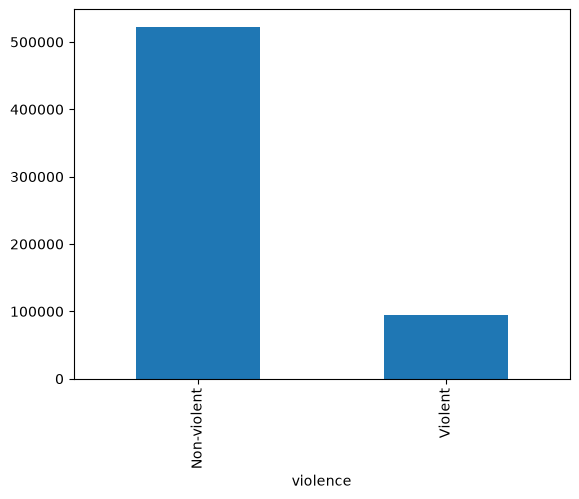

In [157]:
# 4.8 bar chart: violent vs. non-violent
crime_stats['violence'].value_counts().plot.bar()

We can use this to get a sense of, for Phoenix, given crimes, do they tend to be more violent or nonviolent? We can pretty comfortably say that 85% of the time crimes are considered nonviolent. But that's not really helpful. Phoenix is a big city, so we want to look at that broken out by zip code to see trends in different areas.

## 5. Trends by zip code

This section here, we run it a few times. When I first ran this, especially when I was looking at change from the start year to the end year, there were some zip codes that came in later or had very low counts. If we're looking at a percent change, if they had 2 crimes and then they bounced up to 4 or 5 crimes, they see a really big percent change and skew the numbers. So I wanted to show the full group, and then show what happens when we remove the small zip codes that skew the percent change.

### Violent

First, we're going to create a filter. Looking at our violence column, we're defining it's violent if that column states violent for that row.

In [158]:
# 5.1 filter to Violent rows

is_violent = crime_stats[crime_stats['violence']=='Violent']

Then we're defining the start and end years for what we're looking at for ZIPs.

In [ ]:
# 5.2 Violent: ZIP counts for 2016 and for 2024

violent_start_year = is_violent[is_violent['year']==2016].ZIP.value_counts()
violent_end_year = is_violent[is_violent['year']==2024].ZIP.value_counts()

Then we're looking at the data to make sure that we're getting back what's expected here. We can see the top 3 zip codes for the first year, which is 2016, and then the top 3 zip codes for the last year. Most of the zip codes didn't change, but some did.

In [ ]:
# 5.2 check: 2016 counts, top 3
violent_start_year.head(3)

In [ ]:
# 5.2 check: 2024 counts, top 3
violent_end_year.head(3)

#### Violent: first pass, every zip code

And then we want to calculate the percent change to see where they're growing and where they're shrinking.

In [160]:
# 5.3 Violent: percent change 2016 to 2024, all zip codes

violent_change_all = ((violent_end_year - violent_start_year) / violent_start_year * 100).round(2) 

We can see here the percent change, first the ones that are growing. Ascending equals false means it's a descending group.

In [161]:
# 5.4 Violent: top 10 growing, all zip codes
violent_change_all.sort_values(ascending=False).head(10)

ZIP
85087    400.00
85085    320.00
85050    168.75
85307    163.64
85045    150.00
85003    128.30
85255    100.00
85302    100.00
85012     93.48
85083     90.91
Name: count, dtype: float64

And then we're going to look at the shrinking. This is where ascending equals true. A lot with no change.

In [162]:
# 5.4 Violent: top 10 shrinking, all zip codes
violent_change_all.sort_values(ascending=True).head(10)

ZIP
85301   -66.67
85202   -66.67
85251   -50.00
85395   -50.00
85033    -9.29
85353    -2.47
85283     0.00
85018     0.00
85392     0.00
85345     0.00
Name: count, dtype: float64

#### Violent: second pass, without small zip codes

Then we look at the data again, removing those small zip codes, to see if anything does change.

In [163]:
# 5.5 Violent: keep zip codes with more than 50 in 2016

violent_start_year_50 = violent_start_year[violent_start_year > 50]

In [164]:
# 5.6 Violent: percent change 2016 to 2024, large zip codes

violent_change_large = ((violent_end_year[violent_start_year_50.index] - violent_start_year_50) / violent_start_year_50 * 100).round(2)

We can see here that in the top growing, we get a few different ones. Those smaller zip codes are eliminated, and we can see that 85003 had a 128% increase in violent crimes.

In [165]:
# 5.7 Violent: top 10 growing, large zip codes

violent_change_large.sort_values(ascending=False).head(10)

ZIP
85003    128.30
85007     88.00
85004     85.22
85044     81.13
85013     39.88
85020     36.99
85029     35.71
85037     32.61
85014     32.00
85016     31.64
Name: count, dtype: float64

And then same thing, we're going to look at the ones that are shrinking. We get a better viewpoint into those shrinking zip codes, with 85033 leading the pack.

In [166]:
# 5.7 Violent: top 10 shrinking, large zip codes

violent_change_large.sort_values(ascending=True).head(10)

ZIP
85033   -9.29
85353   -2.47
85018    0.00
85053    0.74
85040    4.29
85019    4.84
85254    5.88
85051    7.56
85023    8.23
85031    8.26
Name: count, dtype: float64

### Non-violent

We're going to do the same thing for nonviolent crime. The biggest change in here is swapping out violent for nonviolent, then running all of the same steps: setting is_non_violent to when the column violence says nonviolent for that row,

In [167]:
# 5.1 filter to Non-violent rows

is_non_violent = crime_stats[crime_stats['violence']=='Non-violent']

setting the start year, setting the end year,

In [ ]:
# 5.2 Non-violent: ZIP counts for 2016 and for 2024

non_violent_start_year = is_non_violent[is_non_violent['year']==2016].ZIP.value_counts()
non_violent_end_year = is_non_violent[is_non_violent['year']==2024].ZIP.value_counts()

In [ ]:
# 5.2 check: 2016 counts, top 3
non_violent_start_year.head(3)

In [ ]:
# 5.2 check: 2024 counts, top 3
non_violent_end_year.head(3)

#### Non-violent: first pass, every zip code

calculating the change. I did round these numbers so they were a little bit easier to scan and absorb.

In [169]:
# 5.3 Non-violent: percent change 2016 to 2024, all zip codes

non_violent_change_all = ((non_violent_end_year - non_violent_start_year) / non_violent_start_year * 100).round(2)

We did the same thing here where we looked at the top growing for nonviolent crimes. That doesn't mean these zip codes are becoming more nonviolent, it just means that the nonviolent crime rate is either growing or shrinking. We get some of those big ones again, with that 400% increase

In [170]:
# 5.4 Non-violent: top 10 growing, all zip codes
non_violent_change_all.sort_values(ascending=False).head(10)

ZIP
85383    400.00
85260    375.00
85281    100.00
85201    100.00
85305    100.00
85054     84.45
85087     78.57
85003     43.86
85004     41.10
85307     17.95
Name: count, dtype: float64

or 75% decrease.

In [171]:
# 5.4 Non-violent: top 10 shrinking, all zip codes
non_violent_change_all.sort_values(ascending=True).head(10)

ZIP
85303   -75.00
85083   -57.22
85331   -51.70
85323   -50.00
85392   -50.00
85382   -50.00
85254   -48.23
85301   -47.06
85050   -46.11
85032   -45.36
Name: count, dtype: float64

#### Non-violent: second pass, without small zip codes

And so we're going to remove small zip codes for nonviolent. In this case, we're doing zip codes that have more than 200. The 50 and the 200, you can change those in the notebook. Those are numbers I picked from reviewing the data. It's what I felt was the cutoff for both violent and nonviolent, but those are very easy numbers to swap. You can run a model to calculate the outliers, but we did this quick and dirty.

In [172]:
# 5.5 Non-violent: keep zip codes with more than 200 in 2016

non_violent_start_year_200 = non_violent_start_year[non_violent_start_year > 200]

In [173]:
# 5.6 Non-violent: percent change 2016 to 2024, large zip codes

non_violent_change_large = ((non_violent_end_year[non_violent_start_year_200.index] - non_violent_start_year_200) / non_violent_start_year_200 * 100).round(2)

Then we're starting to get those top growing. We get a better picture of the top growing, where instead of growing by 400%, it's growing by 84.45% for 85054.

In [174]:
# 5.7 Non-violent: top 10 growing, large zip codes

non_violent_change_large.sort_values(ascending=False).head(10)

ZIP
85054    84.45
85003    43.86
85004    41.10
85034    11.96
85085    11.38
85012     4.11
85007     2.53
85016    -2.67
85006    -3.61
85035    -7.97
Name: count, dtype: float64

And same thing for nonviolent shrinking. We can see here that it drops to a decrease of 48% for 85254.

In [175]:
# 5.7 Non-violent: top 10 shrinking, large zip codes

non_violent_change_large.sort_values(ascending=True).head(10)

ZIP
85254   -48.23
85050   -46.11
85032   -45.36
85018   -45.34
85023   -44.19
85033   -40.00
85028   -38.69
85308   -38.21
85048   -37.91
85024   -37.47
Name: count, dtype: float64

### Line charts

That's the output of the data, but we do turn it into some line charts. The first one here is violent crimes per year, from the beginning of 2016 to the end of 2024, putting those in order. It shows that 2020 had the most violent crimes, and that started dwindling down. We started to see a drop again into 2023. 2020 was a very difficult year for a lot of people. A lot of people were cramped up together, a really big disruption to their day-to-day. The lockdowns for the pandemic are one explainer as to why that violent crime rate skyrocketed there and then took a while to pan back down once the repercussions of the pandemic dwindled. I'm starting my line graph from zero to make the changes in crime not look quite so dramatic, but we still have that spike in 2020.

In [ ]:
# 5.8 line chart: violent per year, 2016 to 2024

violent_years = is_violent[(is_violent['year'] >= 2016) & (is_violent['year'] <= 2024)].year.value_counts().sort_index()
plt.xlabel('Year')
plt.plot(violent_years.index, violent_years.values)
plt.ylim(bottom=0)
plt.title('Violent Crimes per Year (2016-2024)')
plt.show()

Same thing for nonviolent crimes here. Nonviolent crimes spiked in 2019, then dropped afterwards.

In [ ]:
# 5.8 line chart: non-violent per year, 2016 to 2024

non_violent_years = is_non_violent[(is_non_violent['year'] >= 2016) & (is_non_violent['year'] <= 2024)].year.value_counts().sort_index()
plt.xlabel('Year')
plt.plot(non_violent_years.index, non_violent_years.values)
plt.ylim(bottom=0)
plt.title('Non-Violent Crimes per Year (2016-2024)')
plt.show()

This can be utilized for the Pre-Crime Unit or the FBI, but honestly, this data can be utilized by different interest groups, police departments, nonprofits interested in working on addressing crimes, or early intervention programs for different communities. If there were communities that had specific policies in place, you can utilize this type of data to see the change in violent or nonviolent crimes across the years for a community. This data would be really useful in a map form, where you can visualize the differences between zip codes and see if there are pockets, hotspots, or cold spots.

## 6. Findings

- 85% of Phoenix crimes are non-violent and 15% are violent.
- Fastest growing violent crime: 85003, 85007, 85004.
- Fastest shrinking violent crime: 85033 and 85353, the only two that dropped.
- Fastest growing non-violent crime: 85054, 85003, 85004.
- Fastest shrinking non-violent crime: 85254, 85050, 85032.
- Violent crime peaked in 2020. Non-violent crime peaked in 2019 and dropped every year after.